# Practical Session 09 &mdash; C. Boosting, and teams of any model

Averaging fixes models that are right on average but jumpy. It cannot fix models that are **stable but
too simple**, off-center every time. Those need a team whose members **correct each other**: boosting.
The second half of the notebook opens the box the other way round: which ensembles accept **any**
model inside, and which one should you use?

| | Notebook | What you do |
|---|---|---|
| A | Why a team beats its members | a guessing crowd, voting by hand, counting, averaging |
| B | Bagging and random forests | build a team from one dataset; the out-of-bag score; random features |
| **C** | **Boosting, and teams of any model** | **AdaBoost and gradient boosting by hand; any model inside; choosing (this notebook)** |

> &#11088; **Key idea.** Boosting builds its models **one after the other**, and each new model
> concentrates on what the team **still gets wrong**. Bagging *averages* experts trained side by side
> and reduces variance; boosting *adds up* corrections and reduces bias: it makes a strong model out of
> weak ones.

AdaBoost and gradient boosting are written by hand on tiny examples (ten points, eight apartments) and
checked against scikit-learn; the rest uses scikit-learn's ensembles on the noisy wave and on real
breast-cancer data.

*Run the cells in order (Shift+Enter). Self-contained and offline; the whole notebook runs in about
two minutes, most of it in sections 8 and 10.*

In [1]:
from fractions import Fraction

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import (AdaBoostClassifier, BaggingClassifier, BaggingRegressor,
                              GradientBoostingClassifier, GradientBoostingRegressor,
                              HistGradientBoostingClassifier, RandomForestClassifier,
                              StackingClassifier, VotingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

from nb_utils import use_style
from nb_data import make_noisy_wave, make_rent8, make_ten_points, noisy_wave_truth, sample_noisy_wave

use_style("notes")
C0, C1, CG, CN = "#0072B2", "#D55E00", "#009E73", "#E69F00"
CP = "#CC79A7"                   # pink, when a fifth color is needed
CX = "0.62"                      # gray, for reference lines
mpl.rcParams["axes.prop_cycle"] = mpl.cycler(color=[C0, C1, CG, CN, CP])   # frozen palette
print("ready")

ready


## 1. The weak learner: a stump

Boosting's members are deliberately **weak**: usually a **stump**, a tree that asks one question. Take
ten small points with two features and two classes (circle and square). For boosting it is convenient
to write the classes as $-1$ (circle) and $+1$ (square), so a vote is just a sum.

The cell tries **every** stump: each feature, each threshold halfway between two neighboring values,
and each way of answering. How many points can one question get right? For comparison it also lists the
questions of a fully grown decision tree on the same points.

36 possible stumps; the best four:
  x1 <= 3.5 ? circle : square   right on 8 of 10
  x2 <= 5.5 ? circle : square   right on 8 of 10
  x1 <= 2.5 ? circle : square   right on 7 of 10
  x1 <= 4.5 ? circle : square   right on 7 of 10

scikit-learn's stump asks x1 <= 3.5 and misses ['P4', 'P5']
a fully grown tree asks 3 questions: x1 <= 3.5, x2 <= 5.5, x2 <= 2.5


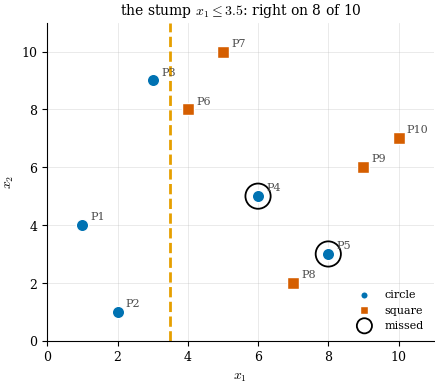

In [2]:
X10, y10 = make_ten_points()
Y10 = np.where(y10 == 1, 1, -1)             # circle = -1, square = +1
P = np.array([f"P{i + 1}" for i in range(10)])

stumps = []                                 # every possible one-question rule
for j in (0, 1):
    values = np.unique(X10[:, j])
    for t in (values[:-1] + values[1:]) / 2:          # halfway between neighboring values
        for yes in (-1, +1):                          # the answer when x_j <= t
            h = np.where(X10[:, j] <= t, yes, -yes)
            stumps.append((int(np.sum(h == Y10)), j, t, yes))
stumps.sort(key=lambda s: -s[0])
LABEL = {-1: "circle", 1: "square"}
print(f"{len(stumps)} possible stumps; the best four:")
for right, j, t, yes in stumps[:4]:
    print(f"  x{j + 1} <= {t:.1f} ? {LABEL[yes]} : {LABEL[-yes]}   right on {right} of 10")

stump = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X10, Y10)       # scikit-learn's stump
miss = stump.predict(X10) != Y10
print(f"\nscikit-learn's stump asks x{stump.tree_.feature[0] + 1} <= {stump.tree_.threshold[0]:.1f} "
      f"and misses {P[miss].tolist()}")
full = DecisionTreeClassifier(random_state=0).fit(X10, Y10).tree_
cuts = [f"x{full.feature[k] + 1} <= {full.threshold[k]:.1f}" for k in range(full.node_count)
        if full.children_left[k] != -1]                      # the internal nodes, top to bottom
print(f"a fully grown tree asks {len(cuts)} questions: {', '.join(cuts)}")

fig, ax = plt.subplots(figsize=(4.4, 3.9))
for lab, c, mk in ((-1, C0, "o"), (1, C1, "s")):
    ax.scatter(*X10[Y10 == lab].T, s=80, color=c, marker=mk, edgecolor="white", label=LABEL[lab])
ax.scatter(*X10[miss].T, s=330, facecolor="none", edgecolor="k", lw=1.3, label="missed")
j, t = stump.tree_.feature[0], stump.tree_.threshold[0]
(ax.axvline if j == 0 else ax.axhline)(t, color=CN, lw=2, ls="--")
for i, (u, v) in enumerate(X10):
    ax.annotate(P[i], (u, v), (6, 4), textcoords="offset points", fontsize=8, color="0.3")
ax.set_xlim(0, 11); ax.set_ylim(0, 11)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.legend(fontsize=8, loc="lower right", markerscale=0.6)
ax.set_title(f"the stump $x_{j + 1}\\leq{t:.1f}$: right on {np.sum(~miss)} of 10", fontsize=10)
plt.show()

The best stump is right on 8 of 10 points; one other question, $x_2\le5.5$, ties with it. A stump is
too simple to get all ten right: **high bias**. Averaging copies of it would not help much, since they
would all ask nearly the same question. Boosting does something else.

## 2. AdaBoost by hand: make the mistakes heavier

AdaBoost in four steps:

1. give every point the same weight, $1/10$;
2. fit a stump to the **weighted** points (scikit-learn's trees accept `sample_weight`);
3. give the stump a **vote**. Its **weighted error** $\varepsilon$ is the total weight of the points it
   misses; the smaller $\varepsilon$, the louder the vote,
   $\alpha=\tfrac12\ln\frac{1-\varepsilon}{\varepsilon}$ (zero for a coin flip, $\varepsilon=\tfrac12$);
4. make its mistakes **heavier** and its successes lighter: rescale so that the missed points carry
   **half** of all the weight and the others the other half. Back to step 2.

The team's answer is the **weighted vote** of all the stumps: the sign of $F=\alpha_1h_1+\alpha_2h_2+\dots$,
where each $h$ answers $-1$ or $+1$. In the pictures a point's size shows its weight at the start of the
round; the missed points are circled.

**Predict first:** after round 2, two stumps vote, and the second one has the bigger vote. Is the
training error lower than with one stump?

round 1: x1 <= 3.5 misses ['P4', 'P5'], weighted error 0.2000, vote 0.6931 -> the team is wrong on ['P4', 'P5']
         new weights: 1/16 1/16 1/16 1/4 1/4 1/16 1/16 1/16 1/16 1/16
round 2: x2 <= 5.5 misses ['P3', 'P8'], weighted error 0.1250, vote 0.9730 -> the team is wrong on ['P3', 'P8']
         new weights: 1/28 1/28 1/4 1/7 1/7 1/28 1/28 1/4 1/28 1/28
round 3: x2 <= 2.5 misses ['P2', 'P6', 'P7', 'P9', 'P10'], weighted error 0.1786, vote 0.7630 -> the team is wrong on []
         new weights: 1/46 1/10 7/46 2/23 2/23 1/10 1/10 7/46 1/10 1/10


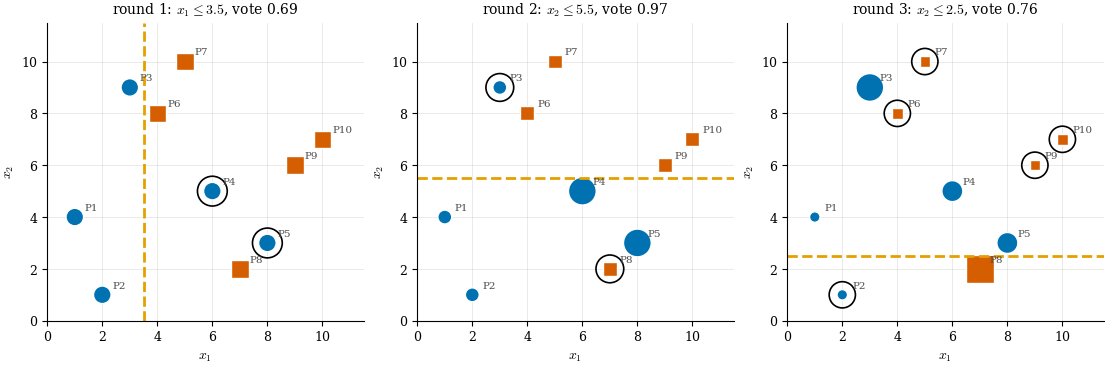

In [3]:
def frac(v):
    "a weight as a simple fraction when it is one, else as a decimal"
    f = Fraction(v).limit_denominator(1000)
    return str(f) if abs(float(f) - v) < 1e-12 else f"{v:.4f}"


ROUNDS = 3                                  # <-- CHANGE ME: more rounds
w = np.full(10, 1 / 10)                     # 1. the same weight for every point
F = np.zeros(10)                            # the team's weighted vote so far
history = []
for m in range(1, ROUNDS + 1):
    stump = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X10, Y10, sample_weight=w)   # 2.
    h = stump.predict(X10)
    miss = h != Y10
    eps = w[miss].sum()                     # the weighted error
    alpha = 0.5 * np.log((1 - eps) / eps)   # 3. the stump's vote
    F += alpha * h
    history.append((stump, w.copy(), miss, alpha))
    j, t = stump.tree_.feature[0], stump.tree_.threshold[0]
    print(f"round {m}: x{j + 1} <= {t:.1f} misses {P[miss].tolist()}, weighted error {eps:.4f}, "
          f"vote {alpha:.4f} -> the team is wrong on {P[np.sign(F) != Y10].tolist()}")
    w[miss] *= 0.5 / w[miss].sum()          # 4. the misses now carry half of all the weight,
    w[~miss] *= 0.5 / w[~miss].sum()        #    and the hits the other half
    print(f"         new weights: {' '.join(frac(v) for v in w)}")

ncols = min(ROUNDS, 3)                      # pictures in rows of three
nrows = -(-ROUNDS // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(3.7 * ncols, 3.7 * nrows), squeeze=False)
for m, (ax, (stump, w_m, miss, alpha)) in enumerate(zip(axes.flat, history), start=1):
    for lab, c, mk in ((-1, C0, "o"), (1, C1, "s")):
        sel = Y10 == lab
        ax.scatter(*X10[sel].T, s=1600 * w_m[sel], color=c, marker=mk, edgecolor="white")
    ax.scatter(*X10[miss].T, s=1600 * w_m[miss] + 300, facecolor="none", edgecolor="k", lw=1.2)
    j, t = stump.tree_.feature[0], stump.tree_.threshold[0]
    (ax.axvline if j == 0 else ax.axhline)(t, color=CN, lw=2, ls="--")
    for i, (u, v) in enumerate(X10):
        ax.annotate(P[i], (u, v), (7, 5), textcoords="offset points", fontsize=7.5, color="0.3")
    ax.set_xlim(0, 11.5); ax.set_ylim(0, 11.5)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_title(f"round {m}: $x_{j + 1}\\leq{t:.1f}$, vote {alpha:.2f}", fontsize=10)
for ax in axes.flat[ROUNDS:]:
    ax.axis("off")
plt.show()

**Round 1:** the stump $x_1\le3.5$ misses P4 and P5 (weighted error 0.2, vote 0.6931). After the update
the two misses weigh **1/4** each and the eight others **1/16** each. On these new weights the stump just
used is a coin flip, so the next stump **must** look somewhere else.

**Round 2:** the best question on the new weights is $x_2\le5.5$, which gets the heavy points P4 and P5
right. Its vote is bigger (0.9730, from a weighted error of 0.125). And the answer to the prediction:
**no**, the team is still wrong on 2 of the 10 points, now P3 and P8. Where the two stumps disagree, the
bigger vote wins, so for now the team just copies stump 2.

**Round 3:** $x_2\le2.5$ misses five points, but they are light (weighted error 0.1786, vote 0.7630).
With three voters the team is right on all ten. And the three questions, $x_1\le3.5$, $x_2\le5.5$,
$x_2\le2.5$, are exactly the questions of the fully grown tree of section 1, found by a team of stumps.

## 3. The same with scikit-learn

`AdaBoostClassifier` runs the same recipe. We give it a stump (`DecisionTreeClassifier(max_depth=1)`)
and the number of rounds, and compare its questions, its votes and its predictions with ours.
scikit-learn's vote of each stump, `estimator_weights_`, leaves out the $\tfrac12$, so it is exactly
twice ours. Doubling every vote changes no decision.

In [4]:
ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=ROUNDS,
                         random_state=0).fit(X10, y10)
ours = [(s.tree_.feature[0], s.tree_.threshold[0]) for s, *_ in history]
theirs = [(s.tree_.feature[0], s.tree_.threshold[0]) for s in ada.estimators_]
print("the same questions, in the same order:", ours == theirs)
print("our votes:             ", np.round([a for *_, a in history], 4))
print("scikit-learn's votes/2:", np.round(ada.estimator_weights_ / 2, 4))
print("the same predictions as our weighted vote:", np.array_equal(ada.predict(X10), (F > 0).astype(int)))
print("training error after each round:", [float(np.mean(p != y10)) for p in ada.staged_predict(X10)])

the same questions, in the same order: True
our votes:              [0.6931 0.973  0.763 ]
scikit-learn's votes/2: [0.6931 0.973  0.763 ]
the same predictions as our weighted vote: True
training error after each round: [0.2, 0.2, 0.0]


Same questions, votes that are exactly half of scikit-learn's, the same predictions, and the same
training error, $0.2\to0.2\to0$.

One warning before moving on. A **mislabeled** point keeps getting missed, so it keeps coming back
heavy, until later stumps bend to fit it: boosting is **sensitive to wrong labels**. (Exercise 3 lets
you watch it happen.)

## 4. From AdaBoost to gradient boosting, by hand

Same idea, another way to point at what is still wrong. AdaBoost makes the missed examples **heavier**.
**Gradient boosting** makes the **leftover error** the next model's target. Think of golf: the first
shot aims at the hole; every next shot starts **where the ball is now** and covers **what is left**,
with a shorter swing.

Eight apartments: predict the rent (hundreds of EUR) from the area (tens of m&sup2;).

* **Stage 0:** predict the average for everyone. The **residual** (true value minus prediction) is what
  is still wrong; the sum of the squared residuals (SSE) is the error to beat.
* **Each stage:** fit a stump to the current residuals, and add a fraction of it (the **learning
  rate**, here 0.5) to the prediction.

The cell runs three stages by hand, then asks `GradientBoostingRegressor` for the same three.

stage 0: predict 7.5 for everyone; residuals from -5.5 to +5.5; SSE 138
stage 1: stump on the residuals: area <= 4.5 ? -4.00 : +4.00  -> predictions [5.5, 9.5], SSE 42
stage 2: stump on the residuals: area <= 4.5 ? -2.00 : +2.00  -> predictions [4.5, 10.5], SSE 18
stage 3: stump on the residuals: area <= 3.5 ? -1.50 : +0.90  -> predictions [3.75, 4.95, 10.95], SSE 9.9

the best single split (one stump fitted to the rents): SSE 10
scikit-learn, same settings: starts at 7.5, SSE after each stage [42.0, 18.0, 9.9]


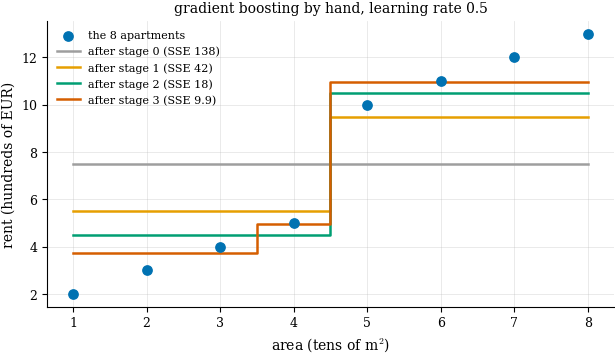

In [5]:
x8, y8 = make_rent8()                       # area (tens of m^2) -> rent (hundreds of EUR)
X8 = x8[:, None]
LEARNING_RATE, STAGES = 0.5, 3              # <-- CHANGE ME: try LEARNING_RATE = 1.0 or 0.1
F8 = np.full(8, y8.mean())                  # stage 0: the average, for everyone
fits = [F8.copy()]
print(f"stage 0: predict {y8.mean()} for everyone; residuals from {np.min(y8 - F8):+.1f} to "
      f"{np.max(y8 - F8):+.1f}; SSE {np.sum((y8 - F8) ** 2):.4g}")
for m in range(1, STAGES + 1):
    r = y8 - F8                             # the residuals: what is still wrong
    stump8 = DecisionTreeRegressor(max_depth=1, random_state=0).fit(X8, r)
    F8 = F8 + LEARNING_RATE * stump8.predict(X8)        # add a fraction of the correction
    fits.append(F8.copy())
    lo, hi = stump8.tree_.value.ravel()[1:3]
    print(f"stage {m}: stump on the residuals: area <= {stump8.tree_.threshold[0]:.1f} ? {lo:+.2f} : {hi:+.2f}"
          f"  -> predictions {np.unique(F8.round(2)).tolist()}, SSE {np.sum((y8 - F8) ** 2):.4g}")

best = DecisionTreeRegressor(max_depth=1, random_state=0).fit(X8, y8)      # one stump on the rents
print(f"\nthe best single split (one stump fitted to the rents): SSE {np.sum((y8 - best.predict(X8)) ** 2):.4g}")
gbr = GradientBoostingRegressor(max_depth=1, learning_rate=LEARNING_RATE, n_estimators=STAGES,
                                random_state=0).fit(X8, y8)
sse_sk = [np.sum((y8 - p) ** 2) for p in gbr.staged_predict(X8)]
print(f"scikit-learn, same settings: starts at {gbr.init_.constant_.ravel()[0]}, "
      f"SSE after each stage {[round(float(v), 4) for v in sse_sk]}")

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.scatter(x8, y8, s=45, color=C0, zorder=5, label="the 8 apartments")
shown = np.unique(np.linspace(0, STAGES, min(STAGES, 5) + 1).round().astype(int))   # at most 6, with the last
for m, c in zip(shown, (CX, CN, CG, C1, CP, C0)):
    ax.step(x8, fits[m], where="mid", color=c, lw=1.8,
            label=f"after stage {m} (SSE {np.sum((y8 - fits[m]) ** 2):.4g})")
ax.set_xlabel("area (tens of m$^2$)")
ax.set_ylabel("rent (hundreds of EUR)")
ax.legend(fontsize=8, loc="upper left")
ax.set_title(f"gradient boosting by hand, learning rate {LEARNING_RATE}", fontsize=10)
plt.show()

Stage 0 predicts 7.5 for everyone, with residuals from $-5.5$ to $+5.5$ and SSE 138. Stage 1 fits a
stump to the residuals (area $\le4.5$? $-4$ : $+4$) and adds **half** of it: $7.5-2=5.5$ on the left,
$7.5+2=9.5$ on the right. The error drops from 138 to 42, then to 18 and 9.9 after stages 2 and 3.
scikit-learn's `GradientBoostingRegressor` starts from the same 7.5 and gives the same errors.

After three tiny stumps the sum fits the training data better than the **best single split** (SSE 10):
a sum of stumps can draw a staircase with more steps than any one stump. Why add only half of each
step? Small steps, many of them, generalize better; sections 6 and 7 show it.

## 5. Watch it learn

The same recipe on the **noisy wave**: 90 points with $y=\sin(1.4x)+0.3x$ plus noise. Each stage fits a
small tree (depth 2) to what is still wrong and adds 0.3 of it. `staged_predict` returns the team's
prediction after every stage, so we can look at stages 1, 5, 20 and 120. The **test error** is measured
against the true curve: the mean squared difference on 600 evenly spaced points.

after   1 stages: training error 0.5070, test error 0.4661
after   5 stages: training error 0.1112, test error 0.0726
after  20 stages: training error 0.0397, test error 0.0282
after 120 stages: training error 0.0030, test error 0.0732


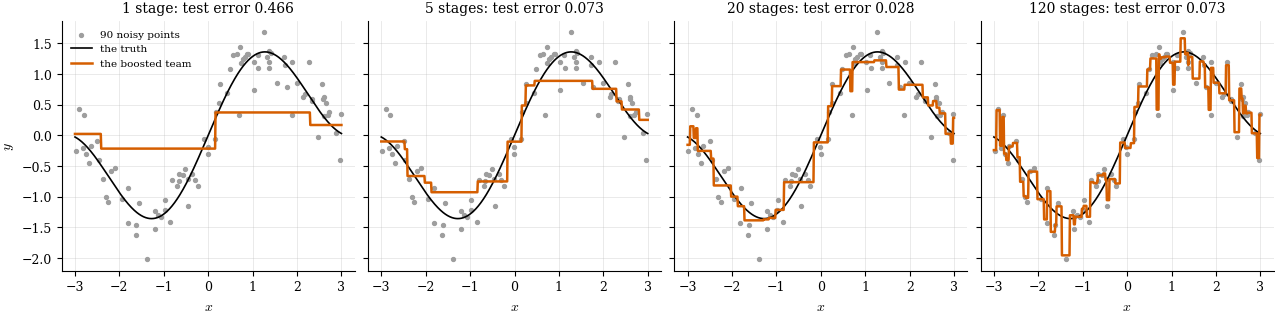

In [6]:
x, y_wave = make_noisy_wave()                     # the 90 training points
grid = np.linspace(-3, 3, 600)
truth = noisy_wave_truth(grid)
gb = GradientBoostingRegressor(n_estimators=120, learning_rate=0.3, max_depth=2,
                               random_state=0).fit(x[:, None], y_wave)
on_grid = list(gb.staged_predict(grid[:, None]))      # the prediction after each stage
on_train = list(gb.staged_predict(x[:, None]))

SHOW = (1, 5, 20, 120)                                 # <-- CHANGE ME: other stages, each from 1 to 120
fig, axes = plt.subplots(1, len(SHOW), figsize=(3.2 * len(SHOW), 3.2), sharey=True, squeeze=False)
for ax, s in zip(axes[0], SHOW):
    train_err = np.mean((on_train[s - 1] - y_wave) ** 2)
    test_err = np.mean((on_grid[s - 1] - truth) ** 2)
    print(f"after {s:3d} stages: training error {train_err:.4f}, test error {test_err:.4f}")
    ax.scatter(x, y_wave, s=8, color=CX, label="90 noisy points")
    ax.plot(grid, truth, color="k", lw=1.2, label="the truth")
    ax.plot(grid, on_grid[s - 1], color=C1, lw=1.8, label="the boosted team")
    ax.set_title(f"{s} stage{'s' if s > 1 else ''}: test error {test_err:.3f}", fontsize=10)
    ax.set_xlabel("$x$")
axes[0, 0].set_ylabel("$y$")
axes[0, 0].legend(fontsize=7.5, loc="upper left")
plt.show()

Early stages capture the shape: the test error falls from 0.4661 after one stage to 0.0282 after 20.
Late stages bend toward individual noisy points: after 120 stages the training error is down to 0.0030,
but the test error is back up to 0.0732.

## 6. More rounds: bagging settles, boosting can overfit

Bagging's test error settles as trees are added. What happens with boosting? The cell fits 300 bagged
trees and two boosted teams of 300 rounds (depth-2 trees), with learning rate **1.0** (full steps) and
**0.1** (a tenth of each correction), and records the test error after every tree or round.

**Predict first:** you run a gradient-boosting model for 1,000 rounds instead of 100. What happens to
its test error?

bagging: lowest test error 0.0402 (with 140 trees); with 300 trees 0.0415
boosting, learning rate 1.0: lowest test error 0.0444 after 6 rounds; after 300 rounds 0.0933 (training error 0.0000)


boosting, learning rate 0.1: lowest test error 0.0246 after 40 rounds; after 300 rounds 0.0621 (training error 0.0054)
one fully grown tree: test error 0.0933


10 fresh noisy waves: the best of learning rate 0.1 beats the best of 1.0 on 10 of 10


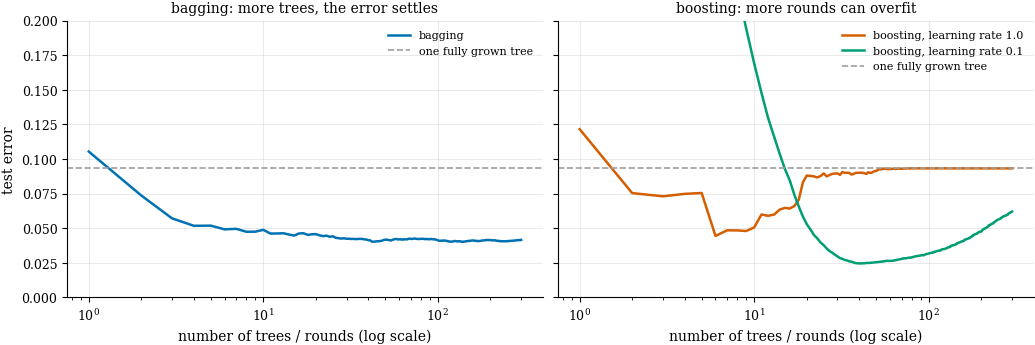

In [7]:
M = 300                                           # <-- CHANGE ME: try 1000 (a few seconds)
bag = BaggingRegressor(DecisionTreeRegressor(random_state=0), n_estimators=M,
                       random_state=0).fit(x[:, None], y_wave)
P_bag = np.array([tree.predict(grid[:, None]) for tree in bag.estimators_])
bag_err = np.mean((np.cumsum(P_bag, axis=0) / np.arange(1, M + 1)[:, None] - truth) ** 2, axis=1)
print(f"bagging: lowest test error {bag_err.min():.4f} (with {bag_err.argmin() + 1} trees); "
      f"with {M} trees {bag_err[-1]:.4f}")

curves = {}
for lr in (1.0, 0.1):                             # <-- CHANGE ME: other learning rates
    gbm = GradientBoostingRegressor(n_estimators=M, learning_rate=lr, max_depth=2,
                                    random_state=0).fit(x[:, None], y_wave)
    curves[lr] = np.array([np.mean((p - truth) ** 2) for p in gbm.staged_predict(grid[:, None])])
    train_end = np.mean((gbm.predict(x[:, None]) - y_wave) ** 2)
    print(f"boosting, learning rate {lr}: lowest test error {curves[lr].min():.4f} after "
          f"{curves[lr].argmin() + 1} rounds; after {M} rounds {curves[lr][-1]:.4f} "
          f"(training error {train_end:.4f})")
deep = DecisionTreeRegressor(random_state=0).fit(x[:, None], y_wave)
deep_err = np.mean((deep.predict(grid[:, None]) - truth) ** 2)
print(f"one fully grown tree: test error {deep_err:.4f}")

# one training set can be lucky: the best test error of each learning rate on 10 fresh noisy waves
rng = np.random.default_rng(7)
wins = 0
for _ in range(10):
    xs, ys = sample_noisy_wave(rng)
    best = {}
    for lr in (1.0, 0.1):
        model = GradientBoostingRegressor(n_estimators=M, learning_rate=lr, max_depth=2,
                                          random_state=0).fit(xs[:, None], ys)
        best[lr] = min(np.mean((p - truth) ** 2) for p in model.staged_predict(grid[:, None]))
    wins += best[0.1] < best[1.0]
print(f"10 fresh noisy waves: the best of learning rate 0.1 beats the best of 1.0 on {wins} of 10")

fig, (axl, axr) = plt.subplots(1, 2, figsize=(10.4, 3.5), sharey=True)
rounds = np.arange(1, M + 1)
axl.plot(rounds, bag_err, color=C0, lw=1.8, label="bagging")
for lr, c in zip(curves, (C1, CG, CN, CP)):
    axr.plot(rounds, curves[lr], color=c, lw=1.8, label=f"boosting, learning rate {lr}")
for ax, title in ((axl, "bagging: more trees, the error settles"),
                  (axr, "boosting: more rounds can overfit")):
    ax.axhline(deep_err, color=CX, ls="--", lw=1.2, label="one fully grown tree")
    ax.set_xscale("log")
    ax.set_xlabel("number of trees / rounds (log scale)")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, loc="upper right")
axl.set_ylabel("test error")
axl.set_ylim(0, 0.2)
plt.show()

**Bagging** settles: its lowest error, 0.0402, and its error with 300 trees, 0.0415, are nearly the
same. **Boosting** never stops fitting the training data. With learning rate 1.0 the test error is
lowest after 6 rounds (0.0444); then the model fits the noise, and after 300 rounds its training error
is 0.0000 (it has memorized the points) and its test error, 0.0933, is that of one overgrown tree.

With learning rate **0.1** each round adds only a tenth of the correction. It needs more rounds (its
best is after 40), but that best, 0.0246, is the lowest test error of all, and on 10 fresh noisy waves
the best of learning rate 0.1 beat the best of 1.0 on 10 of 10. Like salting a soup a pinch at a
time: many small corrections beat a few big ones. And it is more forgiving: after 300
rounds it is at 0.0621, not 0.0933. So the answer to the prediction: **boosting can overfit**, and the
number of rounds has to be chosen.

## 7. When to stop: early stopping

The test curve is not available in practice: the test set must stay unseen. **Early stopping** keeps a
part of the *training* data aside (`validation_fraction`) and stops adding rounds when the error on it
has not improved for `n_iter_no_change` rounds. Here 10% of the 90 points (9 points) are set aside, and
the model is allowed up to 1,000 rounds.

In [8]:
def early_stopped(seed):
    "learning rate 0.1, up to 1,000 rounds; stop when 10 rounds bring no gain on the 9 points set aside"
    model = GradientBoostingRegressor(learning_rate=0.1, n_estimators=1000, max_depth=2,
                                      validation_fraction=0.1, n_iter_no_change=10,  # <-- CHANGE ME
                                      random_state=seed).fit(x[:, None], y_wave)
    return model.n_estimators_, np.mean((model.predict(grid[:, None]) - truth) ** 2)


rounds_used, err_es = early_stopped(seed=0)
print(f"early stopping: stopped after {rounds_used} rounds, test error {err_es:.4f}")
print(f"for comparison, the best round on the test curve: {curves[0.1].argmin() + 1} rounds, "
      f"test error {curves[0.1].min():.4f}" if 0.1 in curves else "")

# which 9 points are set aside is random: other choices, other stopping points
for seed in range(1, 5):
    rounds_used, err_es = early_stopped(seed)
    print(f"  points set aside with seed {seed}: stopped after {rounds_used:3d} rounds, test error {err_es:.4f}")

early stopping: stopped after 39 rounds, test error 0.0250
for comparison, the best round on the test curve: 40 rounds, test error 0.0246
  points set aside with seed 1: stopped after  33 rounds, test error 0.0290
  points set aside with seed 2: stopped after  95 rounds, test error 0.0366
  points set aside with seed 3: stopped after  49 rounds, test error 0.0272
  points set aside with seed 4: stopped after  94 rounds, test error 0.0328


With the first choice of held-out points, early stopping stops after 39 rounds with test error 0.0250,
almost exactly the best round of the test curve (40 rounds, 0.0246), and it never looked at the test
curve. That was partly luck: with other random choices of the 9 held-out points it stops anywhere from
33 to 95 rounds, with test errors from 0.0272 to 0.0366. So early stopping lands in the right region
(33 to 95 rounds, far from the 1,000 allowed), at some cost: its test error, 0.0250 to 0.0366, is above
the best 0.0246, which nobody can know without the test curve, but far below 0.0621 after 300 rounds.
With only 9 points set aside, the stop is jumpy.

The recipe for boosting: a **small learning rate**, **many** rounds allowed, and **early stopping**.
Overfitting signs to look for: training accuracy far above test accuracy. The cures: a smaller learning
rate with early stopping, fewer rounds or shallower trees, and a look at the labels (boosting chases
wrong ones).

## 8. Not only trees: any model inside

Bagging and AdaBoost are **wrappers**: you choose the model that goes inside with `estimator=`. To try
it we need real data: the **breast-cancer** data (569 tumors, 30 measurements each, malignant or benign),
and 10 train/test splits of it, from **5-fold cross-validation run twice** (the data is cut into 5
parts, each part is the test set once, and the whole thing is repeated with another random cut). Some
models need features on comparable scales, so each split standardizes the data with the means and
spreads of its **training part** only.

In [9]:
data = load_breast_cancer()
Xc, yc = data.data, data.target                    # target: 0 = malignant, 1 = benign
print(f"{Xc.shape[0]} tumors, {Xc.shape[1]} measurements each: {np.sum(yc == 0)} malignant, "
      f"{np.sum(yc == 1)} benign")
splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=0).split(Xc, yc))
print(f"{len(splits)} splits, each with {len(splits[0][0])} training and {len(splits[0][1])} test tumors")


def scaled(train, test):
    "standardize both parts with the means and spreads of the training part only"
    scaler = StandardScaler().fit(Xc[train])
    return scaler.transform(Xc[train]), scaler.transform(Xc[test])

569 tumors, 30 measurements each: 212 malignant, 357 benign
10 splits, each with 455 training and 114 test tumors


Four kinds of model, each alone, inside `BaggingClassifier` (100 members) and inside
`AdaBoostClassifier` (100 rounds):

* a **deep tree**;
* **naive Bayes** (`GaussianNB`), simple and fast;
* **k-NN** (k nearest neighbors): predict the majority label of the k closest training examples;
* a **logistic regression**.

The loop is written by hand, so you can see every fit. This cell takes about 30 seconds.

**Predict first:** which of the four improve inside bagging? Inside AdaBoost?

In [10]:
MODELS = {                       # <-- CHANGE ME: add "stump": lambda: DecisionTreeClassifier(max_depth=1),
    "deep tree": lambda: DecisionTreeClassifier(random_state=0),
    "naive Bayes": lambda: GaussianNB(),
    "k-NN": lambda: KNeighborsClassifier(),
    "logistic regression": lambda: LogisticRegression(max_iter=5000),
}
acc = {name: {"alone": [], "bagging": [], "AdaBoost": []} for name in MODELS}
rounds_run, refused = {name: [] for name in MODELS}, {}
for train, test in splits:
    Xtr, Xte = scaled(train, test)
    for name, make in MODELS.items():
        acc[name]["alone"].append(make().fit(Xtr, yc[train]).score(Xte, yc[test]))
        bagged = BaggingClassifier(make(), n_estimators=100, random_state=0).fit(Xtr, yc[train])
        acc[name]["bagging"].append(bagged.score(Xte, yc[test]))
        try:
            boosted = AdaBoostClassifier(make(), n_estimators=100, random_state=0).fit(Xtr, yc[train])
        except ValueError as err:                  # this model cannot take example weights
            refused[name] = str(err)
            continue
        acc[name]["AdaBoost"].append(boosted.score(Xte, yc[test]))
        rounds_run[name].append(len(boosted.estimators_))      # how many rounds it really ran


def versus(new, old):
    "mean accuracy, its change in points, and in how many splits it is better / worse"
    new, old = np.array(new), np.array(old)
    return (f"{new.mean():.4f} ({100 * (new.mean() - old.mean()):+.1f} points; better in "
            f"{np.sum(new > old)}, worse in {np.sum(new < old)} of 10)")


for name in MODELS:
    alone = acc[name]["alone"]
    if name in refused:
        ada_text = f"refused: {refused[name]}"
    elif max(rounds_run[name]) == 1:
        ada_text = f"stopped after 1 round in all {len(rounds_run[name])} splits"
    else:
        ada_text = versus(acc[name]["AdaBoost"], alone)
    print(f"{name}: alone {np.mean(alone):.4f}\n    bagging  {versus(acc[name]['bagging'], alone)}"
          f"\n    AdaBoost {ada_text}")

deep tree: alone 0.9271
    bagging  0.9561 (+2.9 points; better in 10, worse in 0 of 10)
    AdaBoost stopped after 1 round in all 10 splits
naive Bayes: alone 0.9324
    bagging  0.9332 (+0.1 points; better in 2, worse in 1 of 10)
    AdaBoost 0.9561 (+2.4 points; better in 8, worse in 1 of 10)
k-NN: alone 0.9657
    bagging  0.9657 (+0.0 points; better in 1, worse in 1 of 10)
    AdaBoost refused: KNeighborsClassifier doesn't support sample_weight.
logistic regression: alone 0.9754
    bagging  0.9754 (-0.0 points; better in 1, worse in 2 of 10)
    AdaBoost 0.9675 (-0.8 points; better in 2, worse in 6 of 10)


The same means as bars. A missing AdaBoost bar means that AdaBoost refused the model or stopped after
one round.

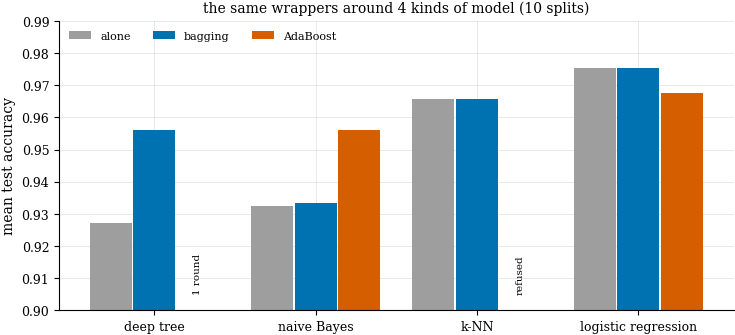

In [11]:
fig, ax = plt.subplots(figsize=(7.4, 3.4))
lowest = min(np.mean(v) for name in MODELS for v in acc[name].values() if len(v))
bottom = min(0.90, np.floor(100 * lowest - 1) / 100)            # room below the lowest bar
labeled = set()
for d, (kind, c) in enumerate((("alone", CX), ("bagging", C0), ("AdaBoost", C1))):
    for i, name in enumerate(MODELS):
        v = acc[name][kind]
        if kind == "AdaBoost" and (name in refused or max(rounds_run[name]) == 1):
            note = "refused" if name in refused else "1 round"
            ax.text(i + (d - 1) * 0.27, bottom + 0.005, note, rotation=90, ha="center", va="bottom",
                    fontsize=7.5)
            continue
        ax.bar(i + (d - 1) * 0.27, np.mean(v), width=0.26, color=c,
               label=None if kind in labeled else kind)
        labeled.add(kind)
ax.set_xticks(range(len(MODELS)), list(MODELS))
ax.set_ylim(bottom, 0.99)
ax.set_ylabel("mean test accuracy")
ax.legend(fontsize=8, loc="upper left", ncol=3)
ax.set_title(f"the same wrappers around {len(MODELS)} kinds of model (10 splits)", fontsize=10)
plt.show()

**Bagging** helps only the jumpy deep tree: +2.9 points, better in all 10 splits. Naive Bayes, k-NN and
the logistic regression are stable; bagging moves them by 0.1 points or less.

**AdaBoost** lifts the too-simple naive Bayes (0.9324 to 0.9561, better in 8 of the 10 splits), makes the
strong logistic regression slightly worse (0.9754 to 0.9675, worse in 6), **refuses** k-NN with an error
(scikit-learn's k-NN cannot take example weights), and **stops at once** with a deep tree: the first tree
makes no training mistakes, so there is nothing left to reweight.

So **any model can go into bagging**, and any model that takes example weights into AdaBoost. But
bagging fixes **jumpy** models and boosting fixes **too simple** ones.

## 9. Teams of different models: voting and stacking

The members of a team do not even have to be the same kind of model. Five different models (the four
above plus a support vector machine, `SVC`), combined three ways:

* **hard voting:** each model votes with its label, and the majority wins;
* **soft voting:** the team averages the models' predicted probabilities;
* **stacking:** a small model on top (a logistic regression) learns how much to trust each member, from
  the members' predictions on training points they were not fitted on (scikit-learn makes these with
  an inner 5-fold split, so a member that memorizes its training data cannot fool the top model).

Same 10 splits, same standardization.

member: deep tree            0.9271
member: k-NN                 0.9657
member: logistic regression  0.9754
member: naive Bayes          0.9324
member: SVM                  0.9736
team: hard voting          0.9745
team: soft voting          0.9719
team: stacking             0.9763

the best member: logistic regression (0.9754); the teams are within 0.35 points of it


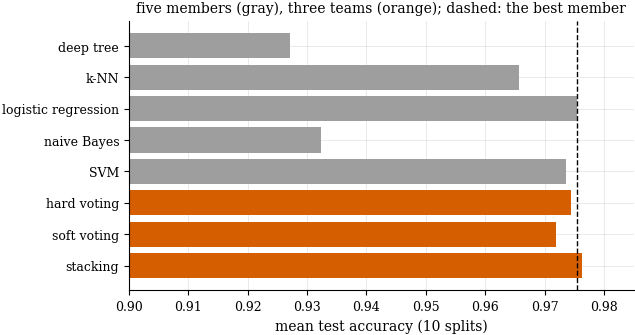

In [12]:
def five_models():
    return [("deep tree", DecisionTreeClassifier(random_state=0)),
            ("k-NN", KNeighborsClassifier()),
            ("logistic regression", LogisticRegression(max_iter=5000)),
            ("naive Bayes", GaussianNB()),
            ("SVM", SVC(probability=True, random_state=0))]


TEAMS = {
    "hard voting": lambda: VotingClassifier(five_models(), voting="hard"),
    "soft voting": lambda: VotingClassifier(five_models(), voting="soft"),
    "stacking": lambda: StackingClassifier(five_models(), final_estimator=LogisticRegression(max_iter=5000)),
}
team_acc = {name: [] for name, _ in five_models()} | {name: [] for name in TEAMS}
for train, test in splits:
    Xtr, Xte = scaled(train, test)
    for name, model in five_models() + [(name, make()) for name, make in TEAMS.items()]:
        team_acc[name].append(model.fit(Xtr, yc[train]).score(Xte, yc[test]))

best_member = max((np.mean(team_acc[name]), name) for name, _ in five_models())
for name, v in team_acc.items():
    print(f"{'team: ' if name in TEAMS else 'member: '}{name:20s} {np.mean(v):.4f}")
print(f"\nthe best member: {best_member[1]} ({best_member[0]:.4f}); the teams are within "
      f"{100 * max(abs(np.mean(team_acc[t]) - best_member[0]) for t in TEAMS):.2f} points of it")

fig, ax = plt.subplots(figsize=(6.4, 3.4))
names = list(team_acc)
ax.barh(names[::-1], [np.mean(team_acc[n]) for n in names[::-1]],
        color=[C1 if n in TEAMS else CX for n in names[::-1]])
ax.axvline(best_member[0], color="k", ls="--", lw=1)
ax.set_xlim(0.90, 0.985)
ax.set_xlabel("mean test accuracy (10 splits)")
ax.set_title("five members (gray), three teams (orange); dashed: the best member", fontsize=10)
plt.show()

Every team lands within half a point of the best member, the logistic regression (0.9754): hard voting
0.9745, soft voting 0.9719, stacking 0.9763. That is the point of a mixed team: you did **not** need to
know in advance which member would be the best. Like every team, voting and stacking gain most when the
members make **different** mistakes.

**Which methods work with any model?**

| | what can go inside | in scikit-learn |
|---|---|---|
| **bagging** | **any** model | `BaggingClassifier` / `BaggingRegressor` |
| **voting** | **any** models, of different kinds | `VotingClassifier` / `VotingRegressor` |
| **stacking** | **any** models, plus one model on top | `StackingClassifier` / `StackingRegressor` |
| **AdaBoost** | in scikit-learn's classifier, only models that take example **weights** (`sample_weight`); `AdaBoostRegressor` resamples the data by weight instead, so it takes any model | `AdaBoostClassifier` / `AdaBoostRegressor` |
| **random forest** | **trees** only | `RandomForestClassifier` / `RandomForestRegressor` |
| **gradient boosting** | small **trees** (in scikit-learn) | `GradientBoostingClassifier`, `HistGradientBoostingClassifier` (and `...Regressor`) |

Every one of them is used the same way: create it, `fit`, then `predict` (or `score`).

## 10. Head to head on the real data

Last comparison: one tree, bagging and a random forest (200 trees each), gradient boosting, and
`HistGradientBoostingClassifier` (scikit-learn's fast version of gradient boosting), the boosters with
their default settings. Same 10 splits. Trees do not care about the scale of the features, so no
standardization is needed. This cell takes about 30 seconds.

**Predict first:** rank one tree, bagging, a random forest and gradient boosting.

one tree               mean 0.9271, spread over the splits 0.0201
bagging                mean 0.9552, spread over the splits 0.0186
random forest          mean 0.9649, spread over the splits 0.0141
gradient boosting      mean 0.9631, spread over the splits 0.0146
HistGradientBoosting   mean 0.9692, spread over the splits 0.0071

ensembles minus one tree: 2.8 to 4.2 points; between the ensembles: at most 1.4 points
  bagging vs random forest: -0.97 points; better in 1, tied in 2, worse in 7 of 10 splits
  bagging vs gradient boosting: -0.79 points; better in 2, tied in 2, worse in 6 of 10 splits
  bagging vs HistGradientBoosting: -1.40 points; better in 1, tied in 2, worse in 7 of 10 splits
  random forest vs gradient boosting: +0.18 points; better in 6, tied in 1, worse in 3 of 10 splits
  random forest vs HistGradientBoosting: -0.44 points; better in 1, tied in 4, worse in 5 of 10 splits
  gradient boosting vs HistGradientBoosting: -0.61 points; better in 1, tied in 4, worse in 5 of 1

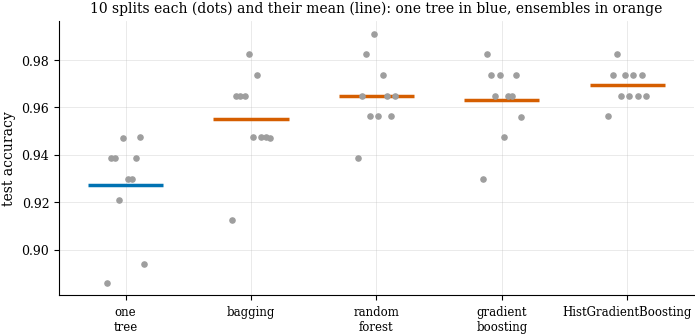

In [13]:
CONTENDERS = {
    "one tree": lambda: DecisionTreeClassifier(random_state=0),
    "bagging": lambda: BaggingClassifier(DecisionTreeClassifier(random_state=0), n_estimators=200,
                                         random_state=0),
    "random forest": lambda: RandomForestClassifier(n_estimators=200, random_state=0),
    "gradient boosting": lambda: GradientBoostingClassifier(random_state=0),
    "HistGradientBoosting": lambda: HistGradientBoostingClassifier(random_state=0),
}
h2h = {name: [] for name in CONTENDERS}
for train, test in splits:
    for name, make in CONTENDERS.items():
        h2h[name].append(make().fit(Xc[train], yc[train]).score(Xc[test], yc[test]))

for name, v in h2h.items():
    print(f"{name:22s} mean {np.mean(v):.4f}, spread over the splits {np.std(v):.4f}")
means = [np.mean(h2h[name]) for name in CONTENDERS if name != "one tree"]
print(f"\nensembles minus one tree: {100 * (min(means) - np.mean(h2h['one tree'])):.1f} to "
      f"{100 * (max(means) - np.mean(h2h['one tree'])):.1f} points; "
      f"between the ensembles: at most {100 * (max(means) - min(means)):.1f} points")

# all models saw the same 10 splits, so compare them split by split
ensembles = [name for name in CONTENDERS if name != "one tree"]
for i, a in enumerate(ensembles):
    for b in ensembles[i + 1:]:
        d = np.array(h2h[a]) - np.array(h2h[b])
        print(f"  {a} vs {b}: {100 * d.mean():+.2f} points; better in {np.sum(d > 0)}, tied in "
              f"{np.sum(d == 0)}, worse in {np.sum(d < 0)} of 10 splits")

fig, ax = plt.subplots(figsize=(7.0, 3.4))
for i, (name, v) in enumerate(h2h.items()):
    ax.scatter(np.full(len(v), i) + np.linspace(-0.15, 0.15, len(v)), v, s=14, color=CX, zorder=4)
    ax.hlines(np.mean(v), i - 0.3, i + 0.3, color=C1 if i else C0, lw=2.5, zorder=3)
ax.set_xticks(range(len(h2h)), [n.replace(" ", "\n") for n in h2h], fontsize=8.5)
ax.set_ylabel("test accuracy")
ax.set_title("10 splits each (dots) and their mean (line): one tree in blue, ensembles in orange",
             fontsize=10)
plt.show()

Every ensemble beats the single tree, by 2.8 to 4.2 points (0.9271 against 0.9552 to 0.9692). All models
saw the same splits, so compare them split by split: plain bagging trails the other three (it is worse
than the forest and than HistGradientBoosting on 7 of the 10 splits, and worse than gradient boosting on
6). Among the forest and the two boosters the mean gaps are at most 0.61 points; HistGradientBoosting
has a small edge (ahead of the forest on 5 splits, tied on 4, behind on 1), but 10 splits of one dataset
make that a hint, not a verdict: **no clear winner** among the three. "Method X always wins" is not a
thing: try a forest and a booster, and compare them on your own data, over several splits.

**Which one should I use?** For tabular data (a table of rows and columns), classification or
regression:

* Must the decisions be explained as a few rules? Use a **single small tree**, and accept less accuracy.
* Otherwise, start with a **random forest** (a few hundred trees, default settings): a strong baseline
  in minutes, little tuning.
* Need the last bit of accuracy, and have time to tune? Try **gradient boosting**
  (`HistGradientBoostingClassifier`, or libraries such as XGBoost and LightGBM) with a small learning
  rate and early stopping, unless many labels are wrong: then keep the forest, because boosting chases
  noise.

## 11. In practice: the knobs that matter, and the code

**Random forest:** `n_estimators`, more trees never make a forest overfit and make it more stable;
beyond a few hundred they stop helping;
`max_features`, the features offered at each split; `min_samples_leaf`, the smallest leaf, that is, the
size of each tree. **Gradient boosting:** `learning_rate`, the size of each correction (small:
0.05&ndash;0.1); `max_iter` (or `n_estimators`), the rounds, let early stopping choose; `max_depth`,
keep each tree small (2&ndash;5).

The whole recipe on one train/test split of the breast-cancer data:

In [14]:
X_train, X_test, y_train, y_test = train_test_split(Xc, yc, test_size=0.25, random_state=0, stratify=yc)

rf = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=0)
rf.fit(X_train, y_train)
print(f"random forest, 500 trees:      test accuracy {rf.score(X_test, y_test):.3f}")

gb = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=1000, early_stopping=True, random_state=0)
gb.fit(X_train, y_train)
print(f"gradient boosting, early stop: test accuracy {gb.score(X_test, y_test):.3f} "
      f"(stopped after {gb.n_iter_} of at most 1000 rounds)")
print(f"\none test point is worth {1 / len(y_test):.3f} of accuracy on these {len(y_test)} test points")

random forest, 500 trees:      test accuracy 0.944
gradient boosting, early stop: test accuracy 0.937 (stopped after 57 of at most 1000 rounds)

one test point is worth 0.007 of accuracy on these 143 test points


## Recap & exercises

On this one split the forest scores 0.944 and the early-stopped booster 0.937, which stopped after 57
rounds. One test point is worth 0.007 here, so they differ by one test point: on one split, that means
nothing. Section 10 compared them over 10 splits.

**Recap.**

* **Boosting** builds weak models one after the other; each concentrates on what the team still gets
  wrong. It reduces **bias**: three stumps found the three questions of a full tree, and the training
  error went $0.2\to0.2\to0$.
* **AdaBoost** makes the missed points heavier (the misses always carry half of the weight) and gives
  each stump a vote, $\alpha=\tfrac12\ln\frac{1-\varepsilon}{\varepsilon}$. scikit-learn's votes are
  twice ours, with the same decisions. It is sensitive to wrong labels.
* **Gradient boosting** fits each new model to the **residuals** and adds a fraction of it (the learning
  rate): SSE $138\to42\to18\to9.9$, better than the best single split (10).
* **More rounds can overfit:** with learning rate 1.0 the test error was lowest after 6 rounds and after
  300 it equaled one overgrown tree (0.0933). A **small learning rate** (0.1: best 0.0246) plus **early
  stopping** (it stopped after 33 to 95 rounds, depending on which 9 points were set aside) is the
  recipe.
* **Any model inside?** Bagging, voting and stacking accept **any** model. AdaBoost accepts any model
  that takes example weights (scikit-learn's k-NN does not, so it was refused). A random forest, and
  gradient boosting in scikit-learn, work with **trees only**. Bagging helps **jumpy** models, boosting
  **too simple** ones.
* **Choosing:** every ensemble beat one tree by about 3 to 4 points; plain bagging trailed the
  forest and the boosters, and among those three there was no clear winner. Start with a random
  forest; try gradient boosting with early stopping when it is worth tuning.

**Exercises.**

1. In &sect;4, set `LEARNING_RATE = 1.0`. After how many stages is the SSE equal to the best single
   split's 10? Then try `LEARNING_RATE = 0.1`: how many stages (`STAGES`) does it need to get below 10?
2. In &sect;2, set `ROUNDS = 6`. Does the training error stay at 0? Which points are the heaviest after
   round 6?
3. **Wrong labels.** In &sect;1, right after `make_ten_points()`, add `y10[9] = 0` (P10, the square in
   the far corner, is now labeled circle). Run &sect;1, &sect;2 and &sect;3 with `ROUNDS = 10` and follow
   P10's weight round after round. After which rounds is it the heaviest point? How many rounds does the
   team need to fit every label, against 3 with the true labels? Which question do rounds 7 and 8 ask,
   and which point is it for?
4. In &sect;6, set the learning rates to `(0.3, 0.05)`. Where is the best round now, and how low does it
   go?
5. In &sect;7, change `validation_fraction` to 0.2 and `n_iter_no_change` to 20. Is the stop steadier
   across the five seeds? Is it better?
6. In &sect;8, add a stump to `MODELS` (the line in the comment). Which wrapper helps it more, and by
   how much? Bagging helps a little too: why, if averaging cannot fix bias? (Hint: with 30 features, do
   stumps fitted to 100 bootstrap samples all ask the same question?)
7. **Write it yourself.** Use the loop of &sect;4 on the noisy wave: 20 stages of
   `DecisionTreeRegressor(max_depth=2)` fitted to the residuals, learning rate 0.3, starting from the
   mean of `y_wave`. Check your predictions against
   `GradientBoostingRegressor(max_depth=2, learning_rate=0.3, n_estimators=20)`.

**Exit ticket.** Answer each question in one or two sentences.

1. Bagging trains every model on ______; boosting trains each model on ______.
2. Why does averaging 100 linear regressions not help?
3. You add 1,000 trees to a random forest, and 1,000 rounds to a gradient-boosting model. What happens
   to each? (Try `M = 1000` in &sect;6: the wave has a single feature, so there a random forest is just
   bagging.)
4. Which of these can be built around a k-NN model: bagging, a random forest, AdaBoost, stacking?
   (&sect;8 and &sect;9 already put k-NN inside bagging, AdaBoost and stacking: read their outputs. Does
   `RandomForestClassifier` even have an argument for the model inside?)